# Economic and Financial Trends Analysis Using Python

## 1. Project Overview
This project analyses monthly aggregate deposits and bank credit of scheduled commercial banks in India from January 2016 to June 2026. The data was obtained from the Reserve Bank of India's Database on Indian Economy (DBIE).

Using Python, the project examines long-term trends, overall and year-on-year growth, the credit-to-deposit ratio, and the gap between deposits and bank credit. The findings are presented through data visualizations and descriptive statistical analysis.
## 2. Research Question
How have bank credit and aggregate deposits in India changed over time, and what can their growth patterns tell us about the banking sector?

## 3. Tools and Data Source
 Tools - Python, Jupyter Notebook, Pandas, NumPy and Matplotlib.
 Data Source - Reserve Bank of India — Database on Indian Economy.

In [1]:
import sys

print(sys.version)
print(sys.executable)

3.14.2 | packaged by Anaconda, Inc. | (main, Dec 19 2025, 11:42:52) [Clang 20.1.8 ]
/opt/anaconda3/envs/namya/bin/python


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import os

print("Current folder:", os.getcwd())
print("Files and folders:", os.listdir())

Current folder: /Users/Namya/Desktop/banking_data _analysis
Files and folders: ['.DS_Store', 'Banking_analysis.ipynb', 'Untitled.ipynb', 'dataset', '.ipynb_checkpoints']


In [4]:
import os

dataset_path = "dataset"

print(os.listdir(dataset_path))

['r803_scheduled_commercial_banks_select_aggregates.csv']


In [5]:
import pandas as pd

file_path = "dataset/r803_scheduled_commercial_banks_select_aggregates.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
df.head()

,src_file,tab,period,row_no,c1,c2,c3,c4,c5,c6,...,c10,c11,c12,c13,c14,c15,c16,c17,c18,c19
0,803--scheduled-commercial-banks-select-aggrega...,All Scheduled Commercial banks,full-history,1,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,803--scheduled-commercial-banks-select-aggrega...,All Scheduled Commercial banks,full-history,2,Scheduled Commercial Banks - Select Aggregates,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,803--scheduled-commercial-banks-select-aggrega...,All Scheduled Commercial banks,full-history,3,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,803--scheduled-commercial-banks-select-aggrega...,All Scheduled Commercial banks,full-history,4,(Rupees Crores),NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,803--scheduled-commercial-banks-select-aggrega...,All Scheduled Commercial banks,full-history,5,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.iloc[0:25, 3:12]

,row_no,c1,c2,c3,c4,c5,c6,c7,c8
0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,Scheduled Commercial Banks - Select Aggregates,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,(Rupees Crores),NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,6,Month\r\n,Demand Deposits,Time Deposits,Aggregate deposits (2+3),Aggregate deposits (2+3) (Adjusted),3 Borrowings from Reserve Bank,Liabilities to Banks,Other demand and time liabilities
6,7,1,2,3,4,5,6,7,8
7,8,Jun - 2026,"35,39,299","2,30,05,412","2,65,44,711",-,"1,47,049","5,51,286","11,82,417"
8,9,May - 2026,"33,12,336","2,26,89,769","2,60,02,106",-,"92,900","5,23,015","12,11,001"
9,10,Apr - 2026,"33,03,489","2,25,65,096","2,58,68,585",-,"32,629","5,27,711","11,31,660"


In [8]:
df.iloc[5].to_dict()

{'src_file': '803--scheduled-commercial-banks-select-aggregates.csv',
 'tab': 'All Scheduled Commercial banks ',
 'period': 'full-history',
 'row_no': 6,
 'c1': 'Month\r\n',
 'c2': 'Demand Deposits',
 'c3': 'Time Deposits',
 'c4': 'Aggregate deposits (2+3)',
 'c5': 'Aggregate deposits (2+3) (Adjusted)',
 'c6': '3 Borrowings from Reserve Bank',
 'c7': 'Liabilities to Banks',
 'c8': 'Other demand and time liabilities',
 'c9': 'Investments in Govt. securities',
 'c10': 'Investments in other approved securities',
 'c11': 'Investment In India(8+9)',
 'c12': 'Investment In India(8+9) (Adjusted)',
 'c13': 'Food credit',
 'c14': 'Non - Food credit',
 'c15': 'Bank Credit (11+12)',
 'c16': 'Bank Credit (11+12) (Adjusted)',
 'c17': 'Cash in hand',
 'c18': 'Balances with RBI',
 'c19': 'Assets with Banks'}

In [9]:
# Keep the actual monthly observations
bank_data = df.iloc[7:].copy()

# Select the date, aggregate deposits, and bank credit columns
bank_data = bank_data[["c1", "c4", "c15"]].copy()

# Give the columns meaningful names
bank_data.columns = ["Month", "Aggregate_Deposits", "Bank_Credit"]

# Reset the row numbers
bank_data = bank_data.reset_index(drop=True)

# Display the first five observations
bank_data.head()

,Month,Aggregate_Deposits,Bank_Credit
0,Jun - 2026,"2,65,44,711","2,19,29,868"
1,May - 2026,"2,60,02,106","2,15,15,402"
2,Apr - 2026,"2,58,68,585","2,12,10,698"
3,Mar - 2026,"2,62,28,787","2,13,59,897"
4,Feb - 2026,"2,51,90,145","2,07,51,207"


In [10]:
bank_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Month               127 non-null    str  
 1   Aggregate_Deposits  126 non-null    str  
 2   Bank_Credit         126 non-null    str  
dtypes: str(3)
memory usage: 3.2 KB


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("dataset/r803_scheduled_commercial_banks_select_aggregates.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [12]:
bank_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Month               127 non-null    str  
 1   Aggregate_Deposits  126 non-null    str  
 2   Bank_Credit         126 non-null    str  
dtypes: str(3)
memory usage: 3.2 KB


In [13]:
bank_data = df.iloc[7:].copy()

bank_data = bank_data[["c1", "c4", "c15"]].copy()

bank_data.columns = ["Month", "Aggregate_Deposits", "Bank_Credit"]

bank_data = bank_data.reset_index(drop=True)

bank_data.head()

,Month,Aggregate_Deposits,Bank_Credit
0,Jun - 2026,"2,65,44,711","2,19,29,868"
1,May - 2026,"2,60,02,106","2,15,15,402"
2,Apr - 2026,"2,58,68,585","2,12,10,698"
3,Mar - 2026,"2,62,28,787","2,13,59,897"
4,Feb - 2026,"2,51,90,145","2,07,51,207"


In [14]:
bank_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 129 entries, 0 to 128
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Month               127 non-null    str  
 1   Aggregate_Deposits  126 non-null    str  
 2   Bank_Credit         126 non-null    str  
dtypes: str(3)
memory usage: 3.2 KB


In [15]:
for col in ["Aggregate_Deposits", "Bank_Credit"]:
    bank_data[col] = (
        bank_data[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    bank_data[col] = pd.to_numeric(
        bank_data[col],
        errors="coerce"
    )

bank_data[["Aggregate_Deposits", "Bank_Credit"]].head()

,Aggregate_Deposits,Bank_Credit
0,26544711.0,21929868.0
1,26002106.0,21515402.0
2,25868585.0,21210698.0
3,26228787.0,21359897.0
4,25190145.0,20751207.0


In [16]:
bank_data["Month"] = pd.to_datetime(
    bank_data["Month"].astype(str).str.strip(),
    format="%b - %Y",
    errors="coerce"
)

bank_data[["Month", "Aggregate_Deposits", "Bank_Credit"]].head()

,Month,Aggregate_Deposits,Bank_Credit
0,2026-06-01,26544711.0,21929868.0
1,2026-05-01,26002106.0,21515402.0
2,2026-04-01,25868585.0,21210698.0
3,2026-03-01,26228787.0,21359897.0
4,2026-02-01,25190145.0,20751207.0


In [17]:
print("Missing values in each column:")
print(bank_data.isnull().sum())

Missing values in each column:
Month                 3
Aggregate_Deposits    3
Bank_Credit           3
dtype: int64


In [18]:
bank_data[bank_data.isnull().any(axis=1)]

,Month,Aggregate_Deposits,Bank_Credit
126,NaT,NaN,NaN
127,NaT,NaN,NaN
128,NaT,NaN,NaN


In [19]:
bank_data = bank_data.dropna(
    subset=["Month", "Aggregate_Deposits", "Bank_Credit"]
).copy()

bank_data = bank_data.reset_index(drop=True)

print("Shape after removing missing rows:", bank_data.shape)
print(bank_data.isnull().sum())

Shape after removing missing rows: (126, 3)
Month                 0
Aggregate_Deposits    0
Bank_Credit           0
dtype: int64


In [20]:
# Sort the data from oldest to newest month
bank_data = bank_data.sort_values("Month").reset_index(drop=True)

# Check the earliest and latest months
print("Earliest month:", bank_data["Month"].min())
print("Latest month:", bank_data["Month"].max())

# Display the first five and last five observations
print("\nFirst five rows:")
display(bank_data.head())

print("\nLast five rows:")
display(bank_data.tail())

Earliest month: 2016-01-01 00:00:00
Latest month: 2026-06-01 00:00:00

First five rows:


,Month,Aggregate_Deposits,Bank_Credit
0,2016-01-01,9218273.0,7055477.0
1,2016-02-01,9299409.0,7144778.0
2,2016-03-01,9327290.0,7249615.0
3,2016-04-01,9525324.0,7232295.0
4,2016-05-01,9514087.0,7226441.0



Last five rows:


,Month,Aggregate_Deposits,Bank_Credit
121,2026-02-01,25190145.0,20751207.0
122,2026-03-01,26228787.0,21359897.0
123,2026-04-01,25868585.0,21210698.0
124,2026-05-01,26002106.0,21515402.0
125,2026-06-01,26544711.0,21929868.0



### 4. Checking Data Consistency

Before performing the analysis, we check whether the dataset contains duplicate months or gaps in the monthly timeline. This helps ensure that the results of our trend analysis are reliable.


In [21]:

# Check for duplicate months
duplicate_months = bank_data["Month"].duplicated().sum()

# Check whether any months are missing
expected_months = pd.date_range(
    start=bank_data["Month"].min(),
    end=bank_data["Month"].max(),
    freq="MS"
)

missing_months = expected_months.difference(bank_data["Month"])

print("Duplicate months:", duplicate_months)
print("Number of expected months:", len(expected_months))
print("Number of actual records:", len(bank_data))
print("Missing months:", len(missing_months))

if len(missing_months) > 0:
    print("Months missing from the dataset:")
    print(missing_months)


Duplicate months: 0
Number of expected months: 126
Number of actual records: 126
Missing months: 0



### 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is the process of examining a dataset to understand its main characteristics, patterns, and unusual values before conducting deeper analysis.

In this project, we will use summary statistics to understand the distribution of aggregate deposits and bank credit across the study period.


In [22]:

# Generate summary statistics for deposits and bank credit
summary_stats = bank_data[
    ["Aggregate_Deposits", "Bank_Credit"]
].describe()

display(summary_stats)


,Aggregate_Deposits,Bank_Credit
count,1.260000e+02,1.260000e+02
mean,1.589416e+07,1.215436e+07
std,4.841528e+06,4.159373e+06
min,9.218273e+06,7.055477e+06
25%,1.167770e+07,8.830981e+06
50%,1.512391e+07,1.083654e+07
75%,1.961785e+07,1.558008e+07
max,2.654471e+07,2.192987e+07



### 6. Trend Analysis of Aggregate Deposits and Bank Credit

Line charts are useful for analysing data over time. We will visualize monthly aggregate deposits and bank credit from January 2016 to June 2026 to identify long-term trends, periods of fluctuation, and changes in the banking sector.


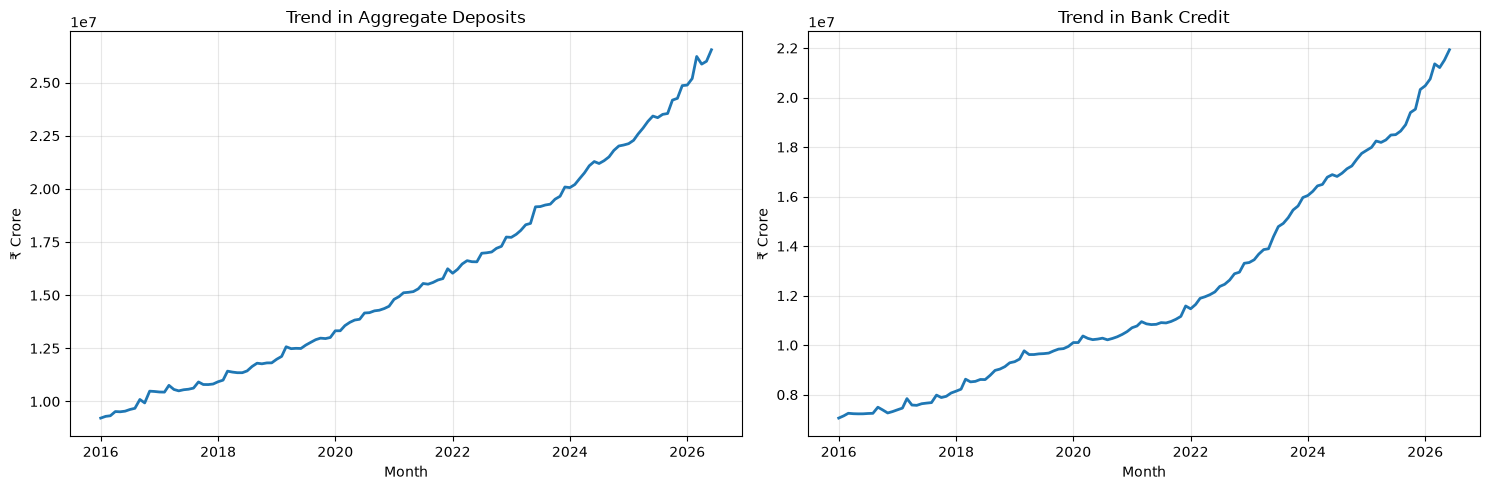

In [23]:

# Create a figure with two side-by-side line charts
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot aggregate deposits
axes[0].plot(
    bank_data["Month"],
    bank_data["Aggregate_Deposits"],
    linewidth=2
)
axes[0].set_title("Trend in Aggregate Deposits")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("₹ Crore")
axes[0].grid(True, alpha=0.3)

# Plot bank credit
axes[1].plot(
    bank_data["Month"],
    bank_data["Bank_Credit"],
    linewidth=2
)
axes[1].set_title("Trend in Bank Credit")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("₹ Crore")
axes[1].grid(True, alpha=0.3)

# Improve layout
plt.tight_layout()
plt.show()



### Interpretation of Trend Charts

The line charts show an overall upward trend in both aggregate deposits and bank credit between January 2016 and June 2026.

Aggregate deposits increased from approximately ₹92 lakh crore to ₹265 lakh crore during the study period. The trend is generally upward, although minor fluctuations are visible across individual months.

Bank credit increased from approximately ₹71 lakh crore to ₹219 lakh crore. Its growth also follows an upward trajectory, with a visibly steeper rise in the later years of the dataset.

These observations suggest substantial long-term growth in both deposits and bank credit. However, the charts alone do not establish the causes of this growth. Further analysis of percentage changes and the relationship between deposits and credit will help quantify these patterns.



### 7. Overall Percentage Growth Analysis

Overall percentage growth measures the relative change in aggregate deposits and bank credit between the beginning and end of the study period.

It allows us to compare the growth of the two financial variables, even though their absolute values differ.


In [24]:

# Get the first and last observations
initial_deposits = bank_data["Aggregate_Deposits"].iloc[0]
final_deposits = bank_data["Aggregate_Deposits"].iloc[-1]

initial_credit = bank_data["Bank_Credit"].iloc[0]
final_credit = bank_data["Bank_Credit"].iloc[-1]

# Calculate overall percentage growth
deposit_growth = (
    (final_deposits - initial_deposits) / initial_deposits
) * 100

credit_growth = (
    (final_credit - initial_credit) / initial_credit
) * 100

# Display the results
print(f"Overall deposit growth: {deposit_growth:.2f}%")
print(f"Overall bank credit growth: {credit_growth:.2f}%")


Overall deposit growth: 187.96%
Overall bank credit growth: 210.82%



### 8. Year-on-Year Growth Analysis

Year-on-year (YoY) growth measures the percentage change in a variable compared with the same month in the previous year.

It helps identify periods of faster or slower growth while reducing the influence of seasonal patterns.

YoY Growth = ((Current Month Value - Value 12 Months Earlier) / Value 12 Months Earlier) × 100


In [26]:

# Calculate year-on-year growth rates
bank_data["Deposit_YoY_Growth"] = (
    bank_data["Aggregate_Deposits"].pct_change(periods=12) * 100
)

bank_data["Credit_YoY_Growth"] = (
    bank_data["Bank_Credit"].pct_change(periods=12) * 100
)

print("YoY growth columns created successfully!")


YoY growth columns created successfully!


In [28]:

# Display the latest 12 months without rounding the date column
latest_growth = bank_data[
    ["Month", "Deposit_YoY_Growth", "Credit_YoY_Growth"]
].tail(12).copy()

latest_growth[["Deposit_YoY_Growth", "Credit_YoY_Growth"]] = (
    latest_growth[["Deposit_YoY_Growth", "Credit_YoY_Growth"]].round(2)
)

display(latest_growth)


,Month,Deposit_YoY_Growth,Credit_YoY_Growth
114,2025-07-01,10.17,10.04
115,2025-08-01,10.22,10.04
116,2025-09-01,9.49,10.38
117,2025-10-01,10.86,12.51
118,2025-11-01,10.18,11.54
119,2025-12-01,12.67,14.54
120,2026-01-01,12.45,14.59
121,2026-02-01,13.04,15.35
122,2026-03-01,16.16,17.08
123,2026-04-01,13.16,16.62



### Interpretation of Year-on-Year Growth

The year-on-year analysis shows that both aggregate deposits and bank credit grew compared with the corresponding months of the previous year.

In June 2026, aggregate deposits recorded year-on-year growth of 13.31%, while bank credit grew by 18.63%. Thus, bank credit growth exceeded deposit growth by 5.32 percentage points.

The results also show an increase in credit growth during the later months of the observed period. Deposit growth strengthened as well, but remained lower than credit growth in the latest months examined.

These findings identify differences in growth patterns, but further analysis is needed to investigate the relationship between deposits and credit.



### 9. Visualizing Year-on-Year Growth

Line charts of year-on-year growth help compare the rate at which aggregate deposits and bank credit change over time. This visualization helps identify periods when growth accelerates, slows down, or differs between the two variables.


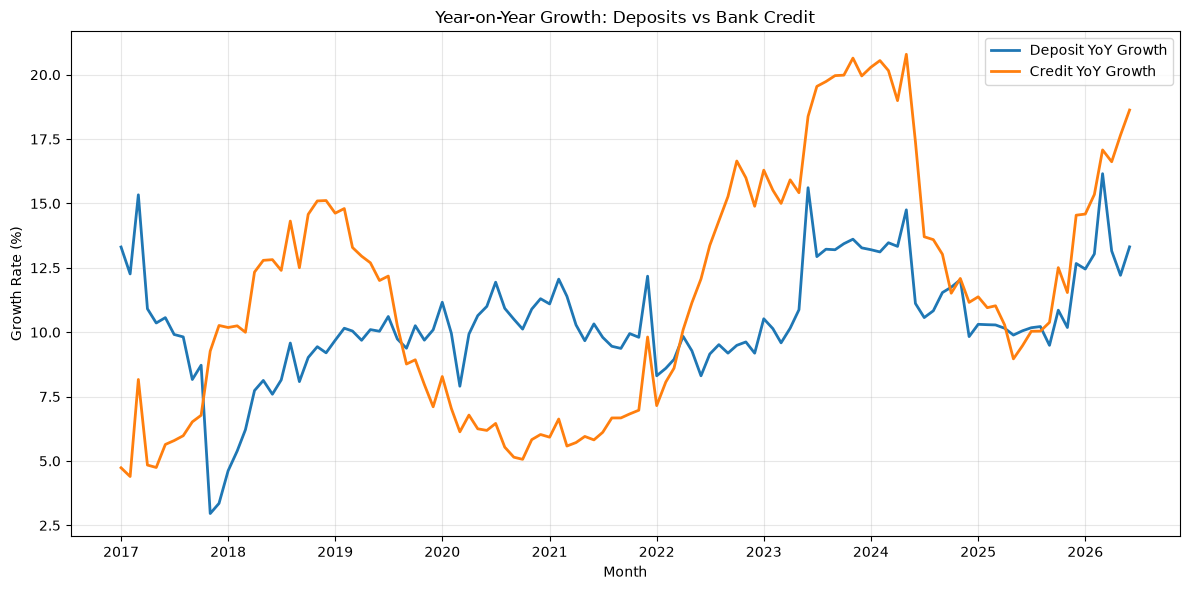

In [29]:

# Create a figure for comparing year-on-year growth
plt.figure(figsize=(12, 6))

# Plot deposit growth
plt.plot(
    bank_data["Month"],
    bank_data["Deposit_YoY_Growth"],
    label="Deposit YoY Growth",
    linewidth=2
)

# Plot credit growth
plt.plot(
    bank_data["Month"],
    bank_data["Credit_YoY_Growth"],
    label="Credit YoY Growth",
    linewidth=2
)

# Add chart details
plt.title("Year-on-Year Growth: Deposits vs Bank Credit")
plt.xlabel("Month")
plt.ylabel("Growth Rate (%)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### Interpretation of Year-on-Year Growth Chart

The year-on-year growth chart shows that deposit and bank credit growth fluctuated considerably during the study period.

Bank credit growth accelerated during parts of 2018–2019 and rose sharply during 2022–2024. Deposit growth also varied, but bank credit growth exceeded deposit growth for much of the later period.

In June 2026, bank credit grew by 18.63% year-on-year, compared with 13.31% for aggregate deposits. This represents a difference of 5.32 percentage points.

The chart highlights periods of changing growth rates, but further analysis is required to understand the relationship between deposits and credit.



### 10. Credit-to-Deposit Ratio Analysis

The credit-to-deposit ratio measures bank credit as a percentage of aggregate deposits. It helps us examine how the amount of credit compares with the deposits held by scheduled commercial banks.

Credit-to-Deposit Ratio = (Bank Credit / Aggregate Deposits) × 100

A rising ratio means bank credit is increasing relative to deposits, while a falling ratio means deposits are increasing relative to credit.


In [30]:

# Calculate the credit-to-deposit ratio
bank_data["Credit_Deposit_Ratio"] = (
    bank_data["Bank_Credit"] / bank_data["Aggregate_Deposits"]
) * 100

# Display the earliest and latest observations
print("First five observations:")
display(
    bank_data[
        ["Month", "Aggregate_Deposits", "Bank_Credit", "Credit_Deposit_Ratio"]
    ].head().round(2)
)

print("Latest five observations:")
display(
    bank_data[
        ["Month", "Aggregate_Deposits", "Bank_Credit", "Credit_Deposit_Ratio"]
    ].tail().round(2)
)



First five observations:


/var/folders/08/vfns8ptn22z2h5rvt5v5nt7c0000gp/T/ipykernel_2008/583597351.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head().round(2)


,Month,Aggregate_Deposits,Bank_Credit,Credit_Deposit_Ratio
0,2016-01-01,9218273.0,7055477.0,76.54
1,2016-02-01,9299409.0,7144778.0,76.83
2,2016-03-01,9327290.0,7249615.0,77.72
3,2016-04-01,9525324.0,7232295.0,75.93
4,2016-05-01,9514087.0,7226441.0,75.96


Latest five observations:


/var/folders/08/vfns8ptn22z2h5rvt5v5nt7c0000gp/T/ipykernel_2008/583597351.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].tail().round(2)


,Month,Aggregate_Deposits,Bank_Credit,Credit_Deposit_Ratio
121,2026-02-01,25190145.0,20751207.0,82.38
122,2026-03-01,26228787.0,21359897.0,81.44
123,2026-04-01,25868585.0,21210698.0,81.99
124,2026-05-01,26002106.0,21515402.0,82.74
125,2026-06-01,26544711.0,21929868.0,82.61



### Interpretation of Credit-to-Deposit Ratio

The credit-to-deposit ratio increased from 76.54% in January 2016 to 82.61% in June 2026, representing a rise of 6.07 percentage points.

This indicates that bank credit increased relative to aggregate deposits over the study period. However, the ratio fluctuated across individual months, and the beginning and ending values alone do not establish a continuous upward trend.

The ratio provides a useful aggregate indicator for comparing credit with deposits, but it should not be interpreted as a direct measure of the proportion of deposits lent out or as a complete measure of banking-sector liquidity.


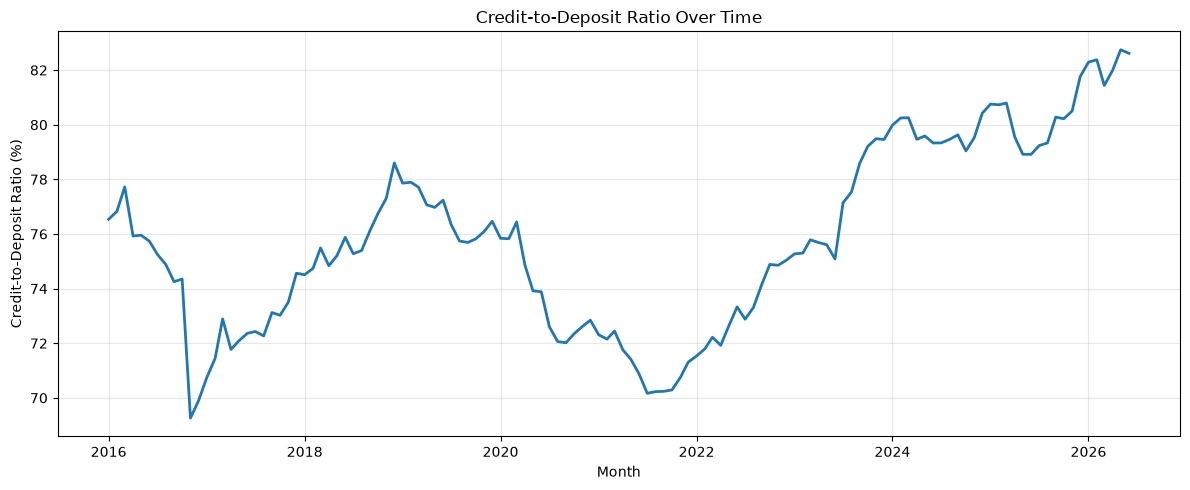

In [31]:

plt.figure(figsize=(12, 5))

plt.plot(
    bank_data["Month"],
    bank_data["Credit_Deposit_Ratio"],
    linewidth=2
)

plt.title("Credit-to-Deposit Ratio Over Time")
plt.xlabel("Month")
plt.ylabel("Credit-to-Deposit Ratio (%)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### Interpretation of Credit-to-Deposit Ratio Trend

The credit-to-deposit ratio fluctuated throughout the study period but showed an overall upward trend. It decreased during parts of 2020–2021 before rising substantially from 2022 onward.

The ratio increased from 76.54% in January 2016 to 82.61% in June 2026, representing an increase of 6.07 percentage points. This indicates that bank credit grew relative to aggregate deposits over the period.

The trend highlights changes in the relationship between credit and deposits. However, the ratio alone cannot establish the causes of these changes or provide a complete assessment of banking-sector liquidity.



### 11. Comparative Analysis of Deposits and Bank Credit

This analysis compares aggregate deposits and bank credit by calculating the difference between them for each month.

The deposit-credit gap helps quantify the difference in their absolute values and shows how this difference changes over time.


In [32]:

# Calculate the difference between deposits and bank credit
bank_data["Deposit_Credit_Gap"] = (
    bank_data["Aggregate_Deposits"] - bank_data["Bank_Credit"]
)

# Display the earliest and latest observations
print("First five observations:")
display(
    bank_data[["Month", "Deposit_Credit_Gap"]]
    .head()
    .assign(
        Deposit_Credit_Gap=lambda x: x["Deposit_Credit_Gap"].round(2)
    )
)

print("Latest five observations:")
display(
    bank_data[["Month", "Deposit_Credit_Gap"]]
    .tail()
    .assign(
        Deposit_Credit_Gap=lambda x: x["Deposit_Credit_Gap"].round(2)
    )
)


First five observations:


,Month,Deposit_Credit_Gap
0,2016-01-01,2162796.0
1,2016-02-01,2154631.0
2,2016-03-01,2077675.0
3,2016-04-01,2293029.0
4,2016-05-01,2287646.0


Latest five observations:


,Month,Deposit_Credit_Gap
121,2026-02-01,4438938.0
122,2026-03-01,4868890.0
123,2026-04-01,4657887.0
124,2026-05-01,4486704.0
125,2026-06-01,4614843.0



### Interpretation of Deposit-Credit Gap

The deposit-credit gap increased from approximately ₹21.63 lakh crore in January 2016 to ₹46.15 lakh crore in June 2026.

This indicates that the absolute difference between aggregate deposits and bank credit became larger over the study period. However, the gap fluctuated across individual months and should not be interpreted as bank profit, cash reserves, or funds directly available for additional lending.


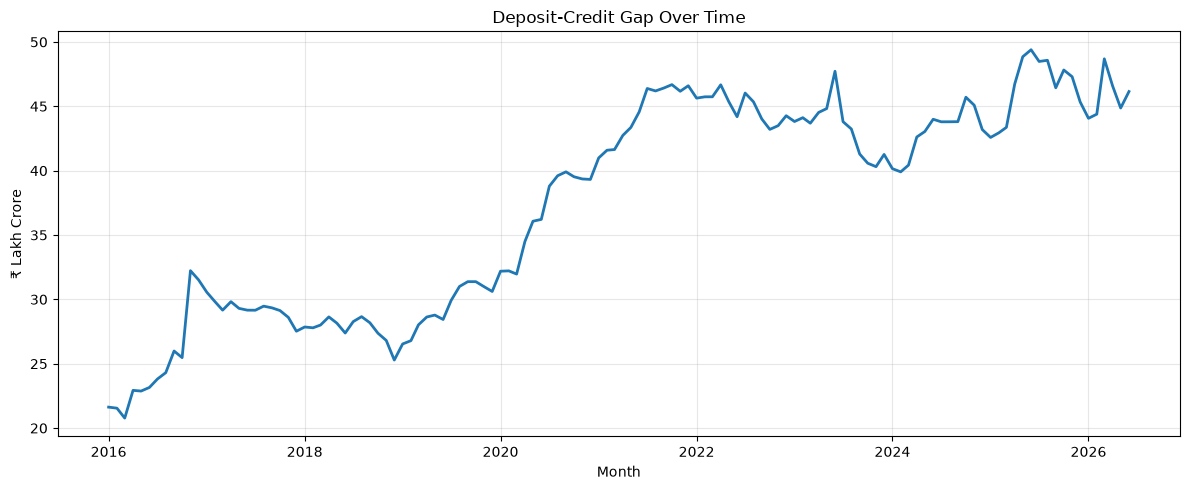

In [33]:

plt.figure(figsize=(12, 5))

plt.plot(
    bank_data["Month"],
    bank_data["Deposit_Credit_Gap"] / 100000,
    linewidth=2
)

plt.title("Deposit-Credit Gap Over Time")
plt.xlabel("Month")
plt.ylabel("₹ Lakh Crore")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### Interpretation of Deposit-Credit Gap Trend

The deposit-credit gap shows an overall upward trend between January 2016 and June 2026, with several periods of fluctuation.

The gap increased from approximately ₹21.63 lakh crore in January 2016 to ₹46.15 lakh crore in June 2026. A substantial increase is visible during 2020–2022, followed by fluctuations at a higher level.

This indicates that the absolute difference between aggregate deposits and bank credit became larger over the study period. The gap should not be interpreted as bank profit, cash reserves, or funds directly available for lending.



### 12. Summary of Key Financial Indicators

This section summarizes the key indicators calculated during the analysis. These include the average credit-to-deposit ratio and the average year-on-year growth rates of aggregate deposits and bank credit.

The indicators provide a concise overview of the relationship between deposits and credit and their growth patterns during the study period.


In [34]:

# Calculate average indicators across the study period
average_deposit_growth = bank_data["Deposit_YoY_Growth"].mean()
average_credit_growth = bank_data["Credit_YoY_Growth"].mean()
average_credit_deposit_ratio = bank_data["Credit_Deposit_Ratio"].mean()

print(f"Average deposit YoY growth: {average_deposit_growth:.2f}%")
print(f"Average credit YoY growth: {average_credit_growth:.2f}%")
print(f"Average credit-to-deposit ratio: {average_credit_deposit_ratio:.2f}%")


Average deposit YoY growth: 10.41%
Average credit YoY growth: 11.46%
Average credit-to-deposit ratio: 75.80%



### Interpretation of Summary Indicators

The average year-on-year growth rate of aggregate deposits was 10.41%, while the average year-on-year growth rate of bank credit was 11.46%. Credit growth therefore exceeded deposit growth by 1.05 percentage points on average.

The average monthly credit-to-deposit ratio was 75.80%, indicating that bank credit was, on average, equivalent to approximately ₹75.80 for every ₹100 of aggregate deposits across the monthly observations.

These averages summarize the overall patterns but do not capture every fluctuation in the data or establish the causes of the observed trends.




## 13. Key Findings

The analysis of monthly data on aggregate deposits and bank credit of scheduled commercial banks in India from January 2016 to June 2026 produced the following findings:

1. **Growth in aggregate deposits:** Aggregate deposits increased by 187.96% between January 2016 and June 2026.

2. **Growth in bank credit:** Bank credit increased by 210.82% over the same period, indicating a larger percentage increase than aggregate deposits.

3. **Year-on-year growth:** Average year-on-year growth was 10.41% for aggregate deposits and 11.46% for bank credit. Credit growth exceeded deposit growth by 1.05 percentage points on average.

4. **Credit-to-deposit ratio:** The ratio increased from 76.54% in January 2016 to 82.61% in June 2026, a rise of 6.07 percentage points.

5. **Deposit-credit gap:** The absolute difference between aggregate deposits and bank credit increased from approximately ₹21.63 lakh crore in January 2016 to ₹46.15 lakh crore in June 2026.

6. **Changing growth patterns:** The visualizations show that deposit and credit growth fluctuated over time, with periods of faster and slower growth rather than a constant rate of increase.



## 14. Conclusion

This project examined the trends in aggregate deposits and bank credit of scheduled commercial banks in India using monthly data from January 2016 to June 2026. Python libraries, including Pandas, NumPy, and Matplotlib, were used to clean the data, calculate financial indicators, and visualize changes over time.

The analysis showed substantial growth in both aggregate deposits and bank credit. Bank credit recorded a higher overall percentage increase and a higher average year-on-year growth rate than aggregate deposits. The credit-to-deposit ratio also increased over the study period, indicating that credit grew relative to deposits.

These findings provide a descriptive overview of changes in the Indian banking sector. However, the analysis does not establish the causes of these changes or assess the financial health of individual banks. Further research incorporating additional economic indicators could provide a deeper understanding of the observed trends.



## 15. Data Source and Methodology

### Data Source

This project uses monthly data on selected aggregates of scheduled commercial banks in India, covering January 2016 to June 2026. The dataset was obtained from the Reserve Bank of India's Database on Indian Economy (DBIE).

The variables selected for analysis were aggregate deposits and bank credit, measured in ₹ crore.

### Methodology

The analysis was conducted using Python in Jupyter Notebook. Pandas was used for data loading, cleaning, and manipulation, while NumPy supported numerical operations and Matplotlib was used for visualization.

The analysis followed these steps:

1. Loaded the original CSV file and selected the required columns.
2. Converted financial values into numeric format and converted monthly observations into dates.
3. Removed rows with missing values and checked for duplicate months and missing months.
4. Calculated descriptive statistics to understand the distribution of deposits and bank credit.
5. Visualized the monthly trends in aggregate deposits and bank credit.
6. Calculated overall percentage growth and year-on-year growth rates.
7. Calculated and visualized the credit-to-deposit ratio and the deposit-credit gap.
8. Summarized the findings using descriptive statistics and trend comparisons.



## 16. Limitations

1. **Aggregate-level data:** The analysis covers scheduled commercial banks as a group and does not compare individual banks.

2. **Descriptive analysis:** The project identifies patterns and changes over time but does not establish causal relationships or explain the reasons behind the observed trends.

3. **Limited variables:** The analysis focuses on aggregate deposits and bank credit. Other indicators, such as interest rates, inflation, GDP growth, and non-performing assets, could provide additional context.

4. **Nominal values:** The financial values are analysed in their reported monetary terms and have not been adjusted for inflation.

5. **Interpretation of the credit-to-deposit ratio:** This ratio compares aggregate bank credit with aggregate deposits but is not, by itself, a complete measure of liquidity or financial stability.



## 17. Future Scope

The project can be extended by incorporating additional economic indicators, such as inflation, GDP growth, and policy interest rates, to examine how banking trends evolve alongside broader economic conditions.

Further improvements could include interactive dashboards, statistical analysis of relationships between variables, and comparisons across different banking categories where suitable data is available.


In [35]:
print("Number of observations:", len(bank_data))
print("First month:", bank_data["Month"].min())
print("Last month:", bank_data["Month"].max())
print("Duplicate months:", bank_data["Month"].duplicated().sum())
print("Missing values in main variables:")
print(bank_data[["Month", "Aggregate_Deposits", "Bank_Credit"]].isna().sum())

Number of observations: 126
First month: 2016-01-01 00:00:00
Last month: 2026-06-01 00:00:00
Duplicate months: 0
Missing values in main variables:
Month                 0
Aggregate_Deposits    0
Bank_Credit           0
dtype: int64


In [36]:

# Verify the main project calculations

first = bank_data.iloc[0]
last = bank_data.iloc[-1]

deposit_growth = (
    (last["Aggregate_Deposits"] - first["Aggregate_Deposits"])
    / first["Aggregate_Deposits"]
) * 100

credit_growth = (
    (last["Bank_Credit"] - first["Bank_Credit"])
    / first["Bank_Credit"]
) * 100

print("Overall deposit growth:", round(deposit_growth, 2), "%")
print("Overall bank credit growth:", round(credit_growth, 2), "%")

print(
    "First-month credit-to-deposit ratio:",
    round(first["Bank_Credit"] / first["Aggregate_Deposits"] * 100, 2),
    "%"
)

print(
    "Last-month credit-to-deposit ratio:",
    round(last["Bank_Credit"] / last["Aggregate_Deposits"] * 100, 2),
    "%"
)

print(
    "First-month deposit-credit gap:",
    round((first["Aggregate_Deposits"] - first["Bank_Credit"]) / 100000, 2),
    "lakh crore"
)

print(
    "Last-month deposit-credit gap:",
    round((last["Aggregate_Deposits"] - last["Bank_Credit"]) / 100000, 2),
    "lakh crore"
)


Overall deposit growth: 187.96 %
Overall bank credit growth: 210.82 %
First-month credit-to-deposit ratio: 76.54 %
Last-month credit-to-deposit ratio: 82.61 %
First-month deposit-credit gap: 21.63 lakh crore
Last-month deposit-credit gap: 46.15 lakh crore
